# 11 · Hybrid architectures (Jamba, Zamba, Samba)

Mamba layers are cheap and carry long context in a fixed-size state, but attention is better at precise
*recall/copying*. **Hybrids interleave both** – e.g. Jamba uses 1 attention layer per 7 Mamba layers, and swaps in
**MoE MLPs** every other layer. The KV cache shrinks ×8 while quality stays Transformer-level.

Here: a 6-layer toy with the pattern `M M A M M A` and MoE on alternating layers.

---

### At a glance

| | |
|---|---|
| **Family** | Hybrid SSM + attention (+MoE) |
| **Representative models** | Jamba, Zamba, Samba, Granite-4 |
| **Core idea** | Interleave a few attention layers with many Mamba layers, and MoE MLPs on alternate layers. |
| **Compute / memory** | small KV cache (few attention layers), mostly O(T) |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 882 s on a laptop CPU |

### What you will learn

- Build a configurable layer pattern
- Compare all-attention, all-Mamba and hybrids
- Inspect attention, MoE routing and Δ in one model

### Contents

1. [Compare 4 designs at the same depth](#1-%C2%B7-Compare-4-designs-at-the-same-depth)
2. [Inside the hybrid: the two attention layers and the MoE routing](#2-%C2%B7-Inside-the-hybrid%3A-the-two-attention-layers-and-the-MoE-routing)
3. [Mamba-layer Δ in the hybrid](#3-%C2%B7-Mamba-layer-%CE%94-in-the-hybrid)

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np, pandas as pd
from llmarch import *
setup_style()
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 400
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

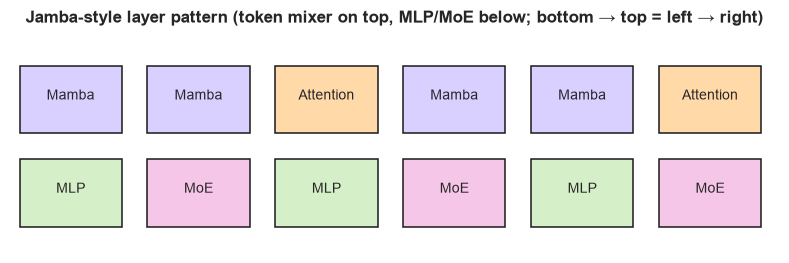

In [2]:
PATTERN = "MMAMMA"; d = 96
def build(pattern, moe_every=2):
    blocks = []
    for i, ch in enumerate(pattern):
        mixer = MambaBlock(d) if ch == "M" else Attention(d, 4, rope=True, bias=False)
        ffn = MoE(d, 4, 2, hidden=96) if (moe_every and i % moe_every == 1) else SwiGLU(d)
        blocks.append(Block(d, mixer, ffn))
    return DecoderLM(V, d, blocks, has_aux=bool(moe_every))
def draw(pattern, moe_every=2, title=""):
    fig, ax = plt.subplots(figsize=(1.5 * len(pattern), 2.6)); ax.axis("off"); ax.set_xlim(0, len(pattern) * 1.5); ax.set_ylim(0, 2.6)
    for i, ch in enumerate(pattern):
        ax.add_patch(plt.Rectangle((i * 1.5 + .1, 1.4), 1.2, .8, fc="#d9d0ff" if ch == "M" else "#ffd9a8", ec="k")); ax.text(i * 1.5 + .7, 1.8, "Mamba" if ch == "M" else "Attention", ha="center", fontsize=9)
        moe = moe_every and i % moe_every == 1; ax.add_patch(plt.Rectangle((i * 1.5 + .1, .3), 1.2, .8, fc="#f6c6e8" if moe else "#d5f0c8", ec="k")); ax.text(i * 1.5 + .7, .7, "MoE" if moe else "MLP", ha="center", fontsize=9)
    ax.set_title(title); plt.show()
draw(PATTERN, 2, "Jamba-style layer pattern (token mixer on top, MLP/MoE below; bottom → top = left → right)")

## 1 · Compare 4 designs at the same depth

In [3]:
designs = {"all-attention": ("AAAAAA", 0), "all-Mamba": ("MMMMMM", 0), "hybrid MMAMMA": ("MMAMMA", 0), "hybrid + MoE": ("MMAMMA", 2)}
models, hists = {}, {}
for n, (pat, me) in designs.items():
    set_seed(0); models[n] = build(pat, me); print("==", n, f"{count_params(models[n]):,} params")
    hists[n] = train_lm(models[n], train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=200, verbose=False)
save_result("11 Hybrid Mamba+Attn+MoE (Jamba-style)", models["hybrid + MoE"], hists["hybrid + MoE"])
kv = {n: designs[n][0].count("A") for n in designs}
df = pd.DataFrame({n: dict(params=count_params(models[n]), attention_layers=kv[n], val_loss=hists[n]["val"][-1]) for n in designs}).T; df

== all-attention 671,040 params


== all-Mamba 847,296 params


== hybrid MMAMMA 788,544 params


== hybrid + MoE 900,288 params


,params,attention_layers,val_loss
all-attention,6.71e+05,6,1.876
all-Mamba,8.473e+05,0,1.678
hybrid MMAMMA,7.885e+05,2,1.727
hybrid + MoE,9.003e+05,2,1.737


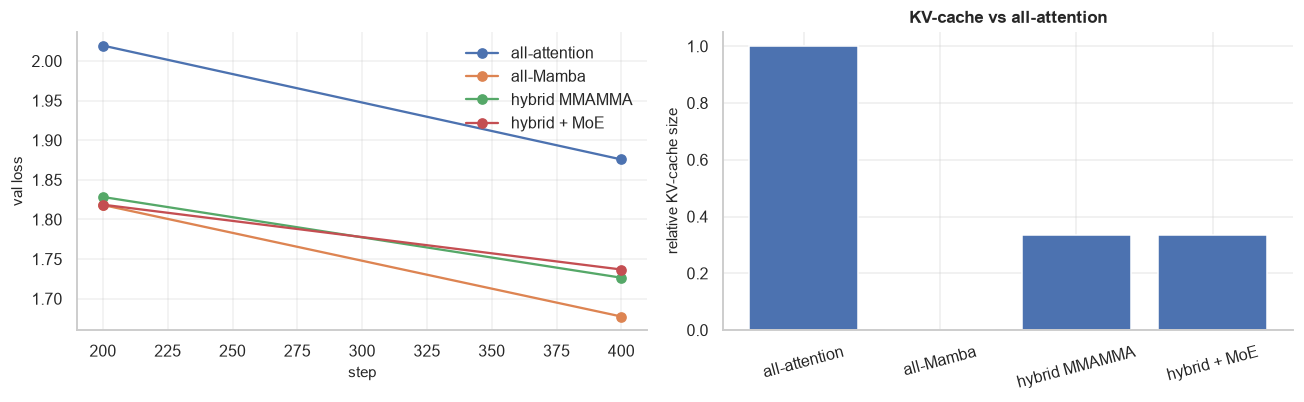

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n, h in hists.items(): ax[0].plot(h["val_step"], h["val"], "o-", label=n)
ax[0].set(xlabel="step", ylabel="val loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar(list(kv), [v / 6 for v in kv.values()]); ax[1].set(ylabel="relative KV-cache size", title="KV-cache vs all-attention"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## 2 · Inside the hybrid: the two attention layers and the MoE routing

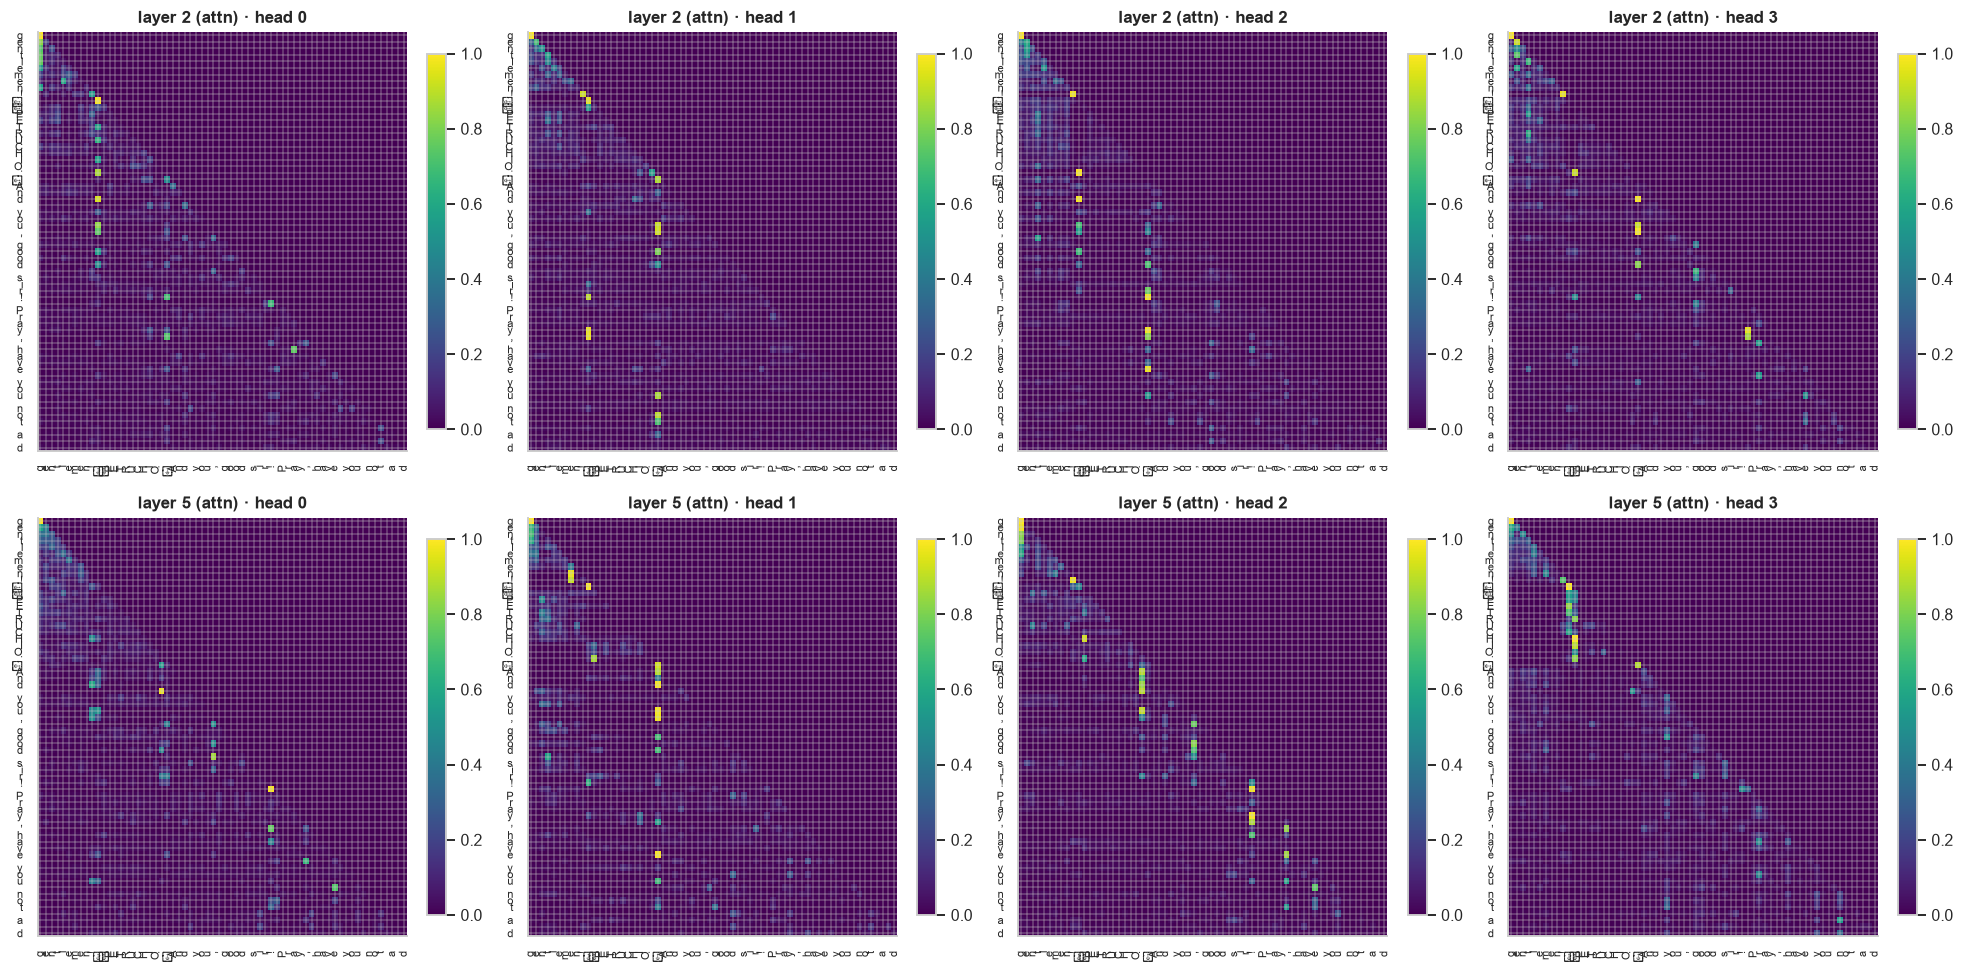

In [5]:
m = models["hybrid + MoE"].eval(); seq = val[100:164]; lab = [("⏎" if c == "\n" else c) for c in data["decode"](seq.tolist())]
for b in m.blocks:
    if isinstance(b.mixer, Attention): b.mixer.keep_attn = True
m(seq[None].to(device)); att_layers = [i for i, b in enumerate(m.blocks) if isinstance(b.mixer, Attention)]
fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for r, li in enumerate(att_layers):
    for h in range(4): plot_heatmap(m.blocks[li].mixer.last_attn[0, h].cpu(), lab, lab, f"layer {li} (attn) · head {h}", ax=axs[r, h])
plt.tight_layout(); plt.show()

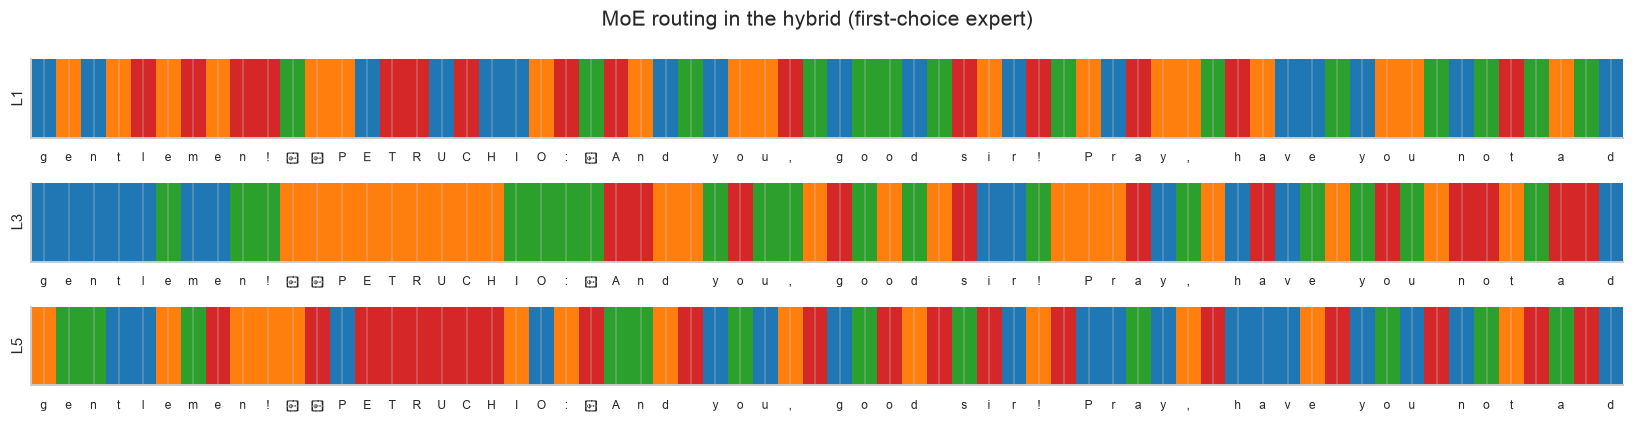

In [6]:
moe_layers = [i for i, b in enumerate(m.blocks) if isinstance(b.ffn, MoE)]
fig, axs = plt.subplots(len(moe_layers), 1, figsize=(15, 1.3 * len(moe_layers)))
for ax, li in zip(axs, moe_layers):
    e = m.blocks[li].ffn.last_idx[0, :, 0].cpu().numpy(); ax.imshow(e[None], cmap="tab10", vmin=0, vmax=9, aspect="auto"); ax.set_xticks(range(64)); ax.set_xticklabels(lab, fontsize=8); ax.set_yticks([]); ax.set_ylabel(f"L{li}")
plt.suptitle("MoE routing in the hybrid (first-choice expert)"); plt.tight_layout(); plt.show()

## 3 · Mamba-layer Δ in the hybrid

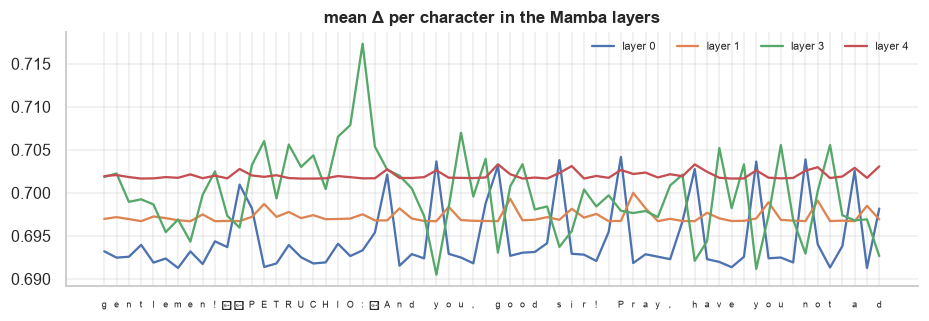

In [7]:
mam = [i for i, b in enumerate(m.blocks) if isinstance(b.mixer, MambaBlock)]
fig, ax = plt.subplots(figsize=(10, 3))
for li in mam: ax.plot(m.blocks[li].mixer.last_dt[0].mean(-1).cpu(), label=f"layer {li}")
ax.set_xticks(range(64)); ax.set_xticklabels(lab, fontsize=6); ax.legend(ncol=4, fontsize=7); ax.set_title("mean Δ per character in the Mamba layers"); plt.show()

---

## Key takeaways

- Attention layers provide precise recall; Mamba layers provide cheap long-range mixing.
- Using 1 attention layer in k divides the KV cache by k.
- MoE adds capacity independently of the token mixer.

## References

- [Lieber et al., *Jamba* (2024)](https://arxiv.org/abs/2403.19887)
- [Glorioso et al., *Zamba* (2024)](https://arxiv.org/abs/2405.16712)

---
*← previous: `10_linear_attention_retnet_rwkv`  ·  next: `12_vision_transformer_and_vlm` →*